# Data Loading

In [1]:
import numpy as np

import scipy.io as sio

import scipy.signal as signal

import scipy.stats as stats
from nltk.sem.relextract import NE_CLASSES


In [2]:
N_TRIALS      = 18

def load_dreamer(mat_path: str) -> dict:
    """
    Load DREAMER.mat and return a cleaned nested dict.

    Returns
    -------
    dreamer : dict  with keys 'subjects' → list of 23 dicts, each containing:
        eeg_stimuli  : list[18]  of np.ndarray (samples, 14)
        eeg_baseline : list[18]  of np.ndarray (baseline_samples, 14)
        ecg_stimuli  : list[18]  of np.ndarray (samples, 2)
        ecg_baseline : list[18]  of np.ndarray (baseline_samples, 2)
        valence      : np.ndarray (18,)  int 1–5
        arousal      : np.ndarray (18,)  int 1–5
        dominance    : np.ndarray (18,)  int 1–5
        age          : str
        gender       : str
    """
    print(f"[LOAD] Reading {mat_path} …")
    raw = sio.loadmat(mat_path, squeeze_me=True, struct_as_record=False)
    dreamer_obj = raw["DREAMER"]

    subjects = []
    data_array = dreamer_obj.Data  # shape (23,)

    for s_idx, subj in enumerate(data_array):
        entry = {
            "age":    str(subj.Age),
            "gender": str(subj.Gender),
            "eeg_stimuli":  [],
            "eeg_baseline": [],
            "ecg_stimuli":  [],
            "ecg_baseline": [],
            "valence":   np.array(subj.ScoreValence,  dtype=np.int32),
            "arousal":   np.array(subj.ScoreArousal,  dtype=np.int32),
            "dominance": np.array(subj.ScoreDominance, dtype=np.int32),
        }

        # EEG trials
        eeg_trials = subj.EEG
        for t in range(N_TRIALS):
            entry["eeg_stimuli"].append( np.array(eeg_trials.stimuli[t],  dtype=np.float32) )
            entry["eeg_baseline"].append(np.array(eeg_trials.baseline[t], dtype=np.float32) )

        # ECG trials
        ecg_trials = subj.ECG
        for t in range(N_TRIALS):
            entry["ecg_stimuli"].append( np.array(ecg_trials.stimuli[t],  dtype=np.float32) )
            entry["ecg_baseline"].append(np.array(ecg_trials.baseline[t], dtype=np.float32) )

        subjects.append(entry)
        print(f"  Subject {s_idx+1:02d}: EEG stim shapes {[x.shape for x in entry['eeg_stimuli'][:2]]} …")

    print(f"[LOAD] Done – {len(subjects)} subjects loaded.\n")
    return {"subjects": subjects}

In [3]:
dreamer = load_dreamer("data/DREAMER.mat")

[LOAD] Reading data/DREAMER.mat …
  Subject 01: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 02: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 03: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 04: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 05: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 06: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 07: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 08: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 09: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 10: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 11: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 12: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 13: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 14: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 15: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 16: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 17: EEG stim

In [4]:
def compute_snr(signal_arr: np.ndarray, noise_arr: np.ndarray) -> float:
    """Signal power / noise power in dB."""
    sig_pwr   = np.mean(signal_arr ** 2)
    noise_pwr = np.mean(noise_arr ** 2)
    return 10 * np.log10(sig_pwr / (noise_pwr + 1e-12))


def quality_report(dreamer: dict) -> None:
    """Print a basic data quality summary for all subjects."""
    print("\n[QC] Quality Control Report")
    print("-" * 55)
    for s_idx, subj in enumerate(dreamer["subjects"]):
        eeg_lens = [x.shape[0] for x in subj["eeg_stimuli"]]
        ecg_lens = [x.shape[0] for x in subj["ecg_stimuli"]]
        print(
            f"  S{s_idx+1:02d} | Age={subj['age']} | Gender={subj['gender']} | "
            f"EEG trial lengths [{min(eeg_lens)}-{max(eeg_lens)}] | "
            f"ECG trial lengths [{min(ecg_lens)}-{max(ecg_lens)}]"
        )

In [5]:
quality_report(dreamer)


[QC] Quality Control Report
-------------------------------------------------------
  S01 | Age=22 | Gender=male | EEG trial lengths [8576-50432] | ECG trial lengths [17152-100864]
  S02 | Age=30 | Gender=female | EEG trial lengths [8576-50432] | ECG trial lengths [17152-100864]
  S03 | Age=27 | Gender=male | EEG trial lengths [8576-50432] | ECG trial lengths [17152-100864]
  S04 | Age=26 | Gender=female | EEG trial lengths [8576-50432] | ECG trial lengths [17152-100864]
  S05 | Age=27 | Gender=female | EEG trial lengths [8576-50432] | ECG trial lengths [17152-100864]
  S06 | Age=25 | Gender=male | EEG trial lengths [8576-50432] | ECG trial lengths [17152-100864]
  S07 | Age=23 | Gender=female | EEG trial lengths [8576-50432] | ECG trial lengths [17152-100864]
  S08 | Age=29 | Gender=male | EEG trial lengths [8576-50432] | ECG trial lengths [17152-100864]
  S09 | Age=31 | Gender=female | EEG trial lengths [8576-50432] | ECG trial lengths [17152-100864]
  S10 | Age=24 | Gender=male | E

# Processing

In [6]:
import numpy as np
from scipy.signal import butter, filtfilt, find_peaks
from scipy.interpolate import interp1d


# DREAMER Constants
FS_EEG = 128
FS_ECG = 256

N_TRIALS = 18


# FILTERING
def butter_bandpass_filter(data,
                           lowcut,
                           highcut,
                           fs,
                           order=4):

    nyq = 0.5 * fs

    low = lowcut / nyq
    high = highcut / nyq

    b, a = butter(order, [low, high], btype='band')

    return filtfilt(b, a, data, axis=0)


# NORMALIZATION
def zscore_normalize(data):

    mean = np.mean(data, axis=0, keepdims=True)

    std = np.std(data, axis=0, keepdims=True) + 1e-8

    return (data - mean) / std


# WINDOWING
def slice_into_windows(data,
                       window_size_samples,
                       hop_size_samples):

    windows = []

    total_samples = data.shape[0]

    start = 0

    while start + window_size_samples <= total_samples:

        end = start + window_size_samples

        windows.append(data[start:end])

        start += hop_size_samples

    return windows


# LABEL MAPPING
def map_to_3_classes(score):

    if score <= 2:
        return 0

    elif score == 3:
        return 1

    else:
        return 2


# HRV EXTRACTION
def extract_hrv_signal(ecg_signal,
                       fs=FS_ECG):

    """
    Converts ECG -> continuous HRV signal.

    Steps:
    1. R-peak detection
    2. RR interval calculation
    3. Interpolation to continuous HRV waveform
    """

    # Use first ECG channel
    if ecg_signal.ndim == 2:
        ecg_1d = ecg_signal[:, 0]
    else:
        ecg_1d = ecg_signal

    # -----------------------------------------------------
    # R-PEAK DETECTION
    # -----------------------------------------------------

    min_distance = int(0.6 * fs)

    peaks, _ = find_peaks(
        ecg_1d,
        distance=min_distance,
        prominence=np.std(ecg_1d) * 0.5
    )

    # Need enough peaks
    if len(peaks) < 3:

        return np.zeros((len(ecg_1d), 1), dtype=np.float16)

    # -----------------------------------------------------
    # RR INTERVALS
    # -----------------------------------------------------

    rr_intervals = np.diff(peaks) / fs

    rr_times = peaks[1:] / fs

    # -----------------------------------------------------
    # INTERPOLATE HRV TO CONTINUOUS SIGNAL
    # -----------------------------------------------------

    time_axis = np.arange(len(ecg_1d)) / fs

    interpolator = interp1d(
        rr_times,
        rr_intervals,
        kind='linear',
        fill_value='extrapolate'
    )

    hrv_signal = interpolator(time_axis)

    hrv_signal = hrv_signal.reshape(-1, 1)

    return hrv_signal.astype(np.float32)


# MAIN PREPARATION FUNCTION
def prepare_dataset_for_cnn(
    dreamer_dict,
    window_duration_sec=10.0,
    overlap_ratio=0.5
):

    eeg_window_len = int(window_duration_sec * FS_EEG)
    eeg_hop_len = int(eeg_window_len * (1 - overlap_ratio))

    ecg_window_len = int(window_duration_sec * FS_ECG)
    ecg_hop_len = int(ecg_window_len * (1 - overlap_ratio))

    # HRV uses ECG sampling rate
    hrv_window_len = ecg_window_len
    hrv_hop_len = ecg_hop_len

    X_eeg = []
    X_ecg = []
    X_hrv = []

    y_valence = []
    y_arousal = []
    y_dominance = []

    groups = []

    print("[PROCESS] Processing EEG + ECG + HRV...")

    for s_idx, subj in enumerate(dreamer_dict["subjects"]):

        subject_id = s_idx

        for t in range(N_TRIALS):

            # LOAD SIGNALS
            raw_eeg = subj["eeg_stimuli"][t]
            # raw_ecg = subj["ecg_stimuli"][t]
            raw_ecg = subj["ecg_stimuli"][t][:, 0:1]

            # FILTERING
            clean_eeg = butter_bandpass_filter(
                raw_eeg,
                lowcut=1.0,
                highcut=45.0,
                fs=FS_EEG
            )

            clean_ecg = butter_bandpass_filter(
                raw_ecg,
                lowcut=0.5,
                highcut=40.0,
                fs=FS_ECG
            )

            # HRV EXTRACTION
            hrv_signal = extract_hrv_signal(
                clean_ecg,
                fs=FS_ECG
            )

            # NORMALIZATION
            norm_eeg = zscore_normalize(clean_eeg)

            norm_ecg = zscore_normalize(clean_ecg)

            norm_hrv = zscore_normalize(hrv_signal)

            # WINDOWING
            eeg_windows = slice_into_windows(
                norm_eeg,
                eeg_window_len,
                eeg_hop_len
            )

            ecg_windows = slice_into_windows(
                norm_ecg,
                ecg_window_len,
                ecg_hop_len
            )

            hrv_windows = slice_into_windows(
                norm_hrv,
                hrv_window_len,
                hrv_hop_len
            )

            # SYNCHRONIZATION
            n_windows = min(
                len(eeg_windows),
                len(ecg_windows),
                len(hrv_windows)
            )

            # LABELS
            class_valence = map_to_3_classes(
                subj["valence"][t]
            )

            class_arousal = map_to_3_classes(
                subj["arousal"][t]
            )

            class_dominance = map_to_3_classes(
                subj["dominance"][t]
            )

            # STORE WINDOWS
            for w in range(n_windows):

                X_eeg.append(eeg_windows[w])

                X_ecg.append(ecg_windows[w])

                X_hrv.append(hrv_windows[w])

                y_valence.append(class_valence)

                y_arousal.append(class_arousal)

                y_dominance.append(class_dominance)

                groups.append(subject_id)

    # FINAL ARRAYS
    X_eeg = np.array(X_eeg, dtype=np.float16)

    X_ecg = np.array(X_ecg, dtype=np.float16)

    X_hrv = np.array(X_hrv, dtype=np.float16)

    groups = np.array(groups, dtype=np.int32)

    y_dict = {

        "valence": np.array(y_valence, dtype=np.int32),

        "arousal": np.array(y_arousal, dtype=np.int32),

        "dominance": np.array(y_dominance, dtype=np.int32)
    }

    # REPORT
    print("\n[PROCESS] Finished!")

    print(f"EEG Shape: {X_eeg.shape}")

    print(f"ECG Shape: {X_ecg.shape}")

    print(f"HRV Shape: {X_hrv.shape}")

    print(f"Groups Shape: {groups.shape}")

    print(f"Unique Subjects: {np.unique(groups)}")

    return (
        X_eeg,
        X_ecg,
        X_hrv,
        y_dict,
        groups
    )

In [7]:
X_eeg, X_ecg, X_hrv, labels, groups = prepare_dataset_for_cnn(dreamer, window_duration_sec=10.0, overlap_ratio=0.5)

[PROCESS] Processing EEG + ECG + HRV...

[PROCESS] Finished!
EEG Shape: (16606, 1280, 14)
ECG Shape: (16606, 2560, 1)
HRV Shape: (16606, 2560, 1)
Groups Shape: (16606,)
Unique Subjects: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22]


# Multimodal CNN

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class MultimodalCNN(nn.Module):

    def __init__(
        self,
        eeg_shape,
        ecg_shape,
        hrv_shape,
        num_classes=3
    ):

        super(MultimodalCNN, self).__init__()

        eeg_timesteps, eeg_channels = eeg_shape
        ecg_timesteps, ecg_channels = ecg_shape
        hrv_timesteps, hrv_channels = hrv_shape

        # EEG STREAM
        # =====================================================

        self.eeg_branch = nn.Sequential(

            nn.Conv1d(
                in_channels=eeg_channels,
                out_channels=32,
                kernel_size=7,
                padding=3
            ),

            nn.BatchNorm1d(32),

            nn.ReLU(),

            nn.MaxPool1d(2),

            nn.Conv1d(
                in_channels=32,
                out_channels=64,
                kernel_size=5,
                padding=2
            ),

            nn.BatchNorm1d(64),

            nn.ReLU(),

            nn.MaxPool1d(2),

            nn.Conv1d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm1d(128),

            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        # ECG STREAM
        # =====================================================

        self.ecg_branch = nn.Sequential(

            nn.Conv1d(
                in_channels=ecg_channels,
                out_channels=32,
                kernel_size=15,
                padding=7
            ),

            nn.BatchNorm1d(32),

            nn.ReLU(),

            nn.MaxPool1d(2),

            nn.Conv1d(
                in_channels=32,
                out_channels=64,
                kernel_size=9,
                padding=4
            ),

            nn.BatchNorm1d(64),

            nn.ReLU(),

            nn.MaxPool1d(2),

            nn.Conv1d(
                in_channels=64,
                out_channels=128,
                kernel_size=5,
                padding=2
            ),

            nn.BatchNorm1d(128),

            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        # HRV STREAM
        # =====================================================

        self.hrv_branch = nn.Sequential(

            nn.Conv1d(
                in_channels=hrv_channels,
                out_channels=16,
                kernel_size=11,
                padding=5
            ),

            nn.BatchNorm1d(16),

            nn.ReLU(),

            nn.MaxPool1d(2),

            nn.Conv1d(
                in_channels=16,
                out_channels=32,
                kernel_size=7,
                padding=3
            ),

            nn.BatchNorm1d(32),

            nn.ReLU(),

            nn.MaxPool1d(2),

            nn.Conv1d(
                in_channels=32,
                out_channels=64,
                kernel_size=5,
                padding=2
            ),

            nn.BatchNorm1d(64),

            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        # FEATURE FUSION
        fusion_features = 128 + 128 + 64

        self.classifier = nn.Sequential(

            nn.Linear(fusion_features, 256),

            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(256, 128),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(128, num_classes)
        )

    # FORWARD
    def forward(self, eeg_input, ecg_input, hrv_input):

        # -----------------------------------------------------
        # Convert:
        # (batch, timesteps, channels)
        # ->
        # (batch, channels, timesteps)
        # -----------------------------------------------------

        eeg_input = eeg_input.permute(0, 2, 1)

        ecg_input = ecg_input.permute(0, 2, 1)

        hrv_input = hrv_input.permute(0, 2, 1)

        # EEG FEATURES
        eeg_features = self.eeg_branch(eeg_input)

        eeg_features = eeg_features.squeeze(-1)

        # ECG FEATURES
        ecg_features = self.ecg_branch(ecg_input)
        ecg_features = ecg_features.squeeze(-1)

        # HRV FEATURES
        hrv_features = self.hrv_branch(hrv_input)

        hrv_features = hrv_features.squeeze(-1)

        # MULTIMODAL FUSION
        combined = torch.cat(
            (
                eeg_features,
                ecg_features,
                hrv_features
            ),
            dim=1
        )

        output = self.classifier(combined)

        return output


# MODEL

model = MultimodalCNN(
    eeg_shape=(1280, 14),
    ecg_shape=(2560, 1),
    hrv_shape=(2560, 1),
    num_classes=3
)

print(model)

MultimodalCNN(
  (eeg_branch): Sequential(
    (0): Conv1d(14, 32, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool1d(output_size=1)
  )
  (ecg_branch): Sequential(
    (0): Conv1d(1, 32, kernel_size=(15,), stride=(1,), padding=(7,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running

# Train & Evalute Loop

In [9]:
import copy, random
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# CUSTOM DATASET
class MultimodalDataset(Dataset):

    def __init__(
        self,
        eeg_data,
        ecg_data,
        hrv_data,
        labels,
        augment=False
    ):

        self.augment = augment

        self.eeg_data = torch.tensor(
            eeg_data,
            dtype=torch.float32
        )

        self.ecg_data = torch.tensor(
            ecg_data,
            dtype=torch.float32
        )

        self.hrv_data = torch.tensor(
            hrv_data,
            dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        eeg = self.eeg_data[idx]

        ecg = self.ecg_data[idx]

        hrv = self.hrv_data[idx]

        if self.augment:

            if random.random() < 0.5:
                eeg = augment_eeg(eeg)

            if random.random() < 0.5:
                ecg = augment_ecg(ecg)

        return (
            eeg,
            ecg,
            hrv,
            self.labels[idx]
        )

# METRICS FUNCTION

def calculate_metrics(y_true, y_pred):

    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),

        "precision": precision_score(
            y_true,
            y_pred,
            average='weighted',
            zero_division=0
        ),

        "recall": recall_score(
            y_true,
            y_pred,
            average='weighted',
            zero_division=0
        ),

        "f1": f1_score(
            y_true,
            y_pred,
            average='weighted',
            zero_division=0
        )
    }

    return metrics


# TRAINING FUNCTION

def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler=None,
    num_epochs=30,
    device='cuda'
):

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "train_f1": [],
        "val_f1": []
    }

    best_model_wts = copy.deepcopy(model.state_dict())
    best_f1 = 0.0

    model.to(device)

    for epoch in range(num_epochs):

        print(f"\nEpoch {epoch+1}/{num_epochs}")
        print("-" * 50)

        # TRAINING

        model.train()

        running_loss = 0.0

        train_preds = []
        train_labels = []

        for eeg_batch, ecg_batch, hrv_batch, labels in train_loader:

            eeg_batch = eeg_batch.to(device)
            ecg_batch = ecg_batch.to(device)
            hrv_batch = hrv_batch.to(device)

            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(eeg_batch, ecg_batch, hrv_batch)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * labels.size(0)

            preds = torch.argmax(outputs, dim=1)

            train_preds.extend(preds.cpu().numpy())
            train_labels.extend(labels.cpu().numpy())

        epoch_train_loss = running_loss / len(train_loader.dataset)

        train_metrics = calculate_metrics(
            train_labels,
            train_preds
        )

        # VALIDATION

        model.eval()

        val_running_loss = 0.0

        val_preds = []
        val_labels = []

        with torch.no_grad():

            for eeg_batch, ecg_batch, hrv_batch, labels in val_loader:

                eeg_batch = eeg_batch.to(device)
                ecg_batch = ecg_batch.to(device)
                hrv_batch = hrv_batch.to(device)
                labels = labels.to(device)

                outputs = model(eeg_batch, ecg_batch, hrv_batch)

                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * labels.size(0)

                preds = torch.argmax(outputs, dim=1)

                val_preds.extend(preds.cpu().numpy())
                val_labels.extend(labels.cpu().numpy())

        epoch_val_loss = val_running_loss / len(val_loader.dataset)

        val_metrics = calculate_metrics(
            val_labels,
            val_preds
        )

        # LEARNING RATE SCHEDULER
        if scheduler is not None:
            scheduler.step(epoch_val_loss)

        # SAVE HISTORY
        history["train_loss"].append(epoch_train_loss)
        history["val_loss"].append(epoch_val_loss)

        history["train_acc"].append(train_metrics["accuracy"])
        history["val_acc"].append(val_metrics["accuracy"])

        history["train_f1"].append(train_metrics["f1"])
        history["val_f1"].append(val_metrics["f1"])

        # SAVE BEST MODEL

        if val_metrics["f1"] > best_f1:

            best_f1 = val_metrics["f1"]

            best_model_wts = copy.deepcopy(model.state_dict())

        # PRINT METRICS

        print(
            f"Train Loss: {epoch_train_loss:.4f} | "
            f"Train Acc: {train_metrics['accuracy']:.4f} | "
            f"Train F1: {train_metrics['f1']:.4f}"
        )

        print(
            f"Val Loss: {epoch_val_loss:.4f} | "
            f"Val Acc: {val_metrics['accuracy']:.4f} | "
            f"Val F1: {val_metrics['f1']:.4f}"
        )

    print("\nTraining Complete")

    model.load_state_dict(best_model_wts)

    return model, history

# EVALUATION FUNCTION
def evaluate_model(model, test_loader, device='cuda'):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for eeg_batch, ecg_batch, hrv_batch, labels in test_loader:

            eeg_batch = eeg_batch.to(device)
            ecg_batch = ecg_batch.to(device)
            hrv_batch = hrv_batch.to(device)

            labels = labels.to(device)

            outputs = model(eeg_batch, ecg_batch, hrv_batch)

            preds = torch.argmax(outputs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    metrics = calculate_metrics(all_labels, all_preds)

    print("\n========== TEST RESULTS ==========")

    for k, v in metrics.items():
        print(f"{k}: {v:.4f}")

    print("\nClassification Report:\n")

    print(
        classification_report(
            all_labels,
            all_preds
        )
    )

    cm = confusion_matrix(all_labels, all_preds)

    return metrics, cm

# Train


In [10]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
import pandas as pd
import numpy as np
import torch
import torch.nn as nn

# DEVICE
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

# DATA
y = labels['valence']

num_samples = X_eeg.shape[0]

n_classes = len(np.unique(y))
n_epochs = 100

print("Number of samples:", num_samples)
print("Number of classes:", n_classes)

# TRAIN / VALIDATION / TEST SPLIT
# First split:
# 70% train
# 30% temp (val + test)

(
    X_train_eeg,
    X_temp_eeg,
    X_train_ecg,
    X_temp_ecg,
    X_train_hrv,
    X_temp_hrv,
    y_train,
    y_temp
) = train_test_split(
    X_eeg,
    X_ecg,
    X_hrv,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split:
# 15% validation
# 15% test

(
    X_val_eeg,
    X_test_eeg,
    X_val_ecg,
    X_test_ecg,
    X_val_hrv,
    X_test_hrv,
    y_val,
    y_test
) = train_test_split(
    X_temp_eeg,
    X_temp_ecg,
    X_temp_hrv,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\nDataset Shapes")

print("Train EEG:", X_train_eeg.shape)
print("Validation EEG:", X_val_eeg.shape)
print("Test EEG:", X_test_eeg.shape)


# DATASETS
train_dataset = MultimodalDataset(
    X_train_eeg,
    X_train_ecg,
    X_train_hrv,
    y_train
)

val_dataset = MultimodalDataset(
    X_val_eeg,
    X_val_ecg,
    X_val_hrv,
    y_val
)

test_dataset = MultimodalDataset(
    X_test_eeg,
    X_test_ecg,
    X_test_hrv,
    y_test
)

# DATALOADERS

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

# MODEL

model = MultimodalCNN(
    eeg_shape=(1280, 14),
    ecg_shape=(2560, 1),
    hrv_shape=(2560, 1),

    num_classes=n_classes
)

model.to(device)

# LOSS FUNCTION
criterion = nn.CrossEntropyLoss()

# OPTIMIZER
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

# LEARNING RATE SCHEDULER
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    patience=3,
    factor=0.5
)

# TRAIN MODEL
model, history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    num_epochs=n_epochs,
    device=device
)

Using device: cuda
Number of samples: 16606
Number of classes: 3

Dataset Shapes
Train EEG: (11624, 1280, 14)
Validation EEG: (2491, 1280, 14)
Test EEG: (2491, 1280, 14)

Epoch 1/100
--------------------------------------------------
Train Loss: 1.0258 | Train Acc: 0.4523 | Train F1: 0.4088
Val Loss: 0.9407 | Val Acc: 0.5500 | Val F1: 0.5101

Epoch 2/100
--------------------------------------------------
Train Loss: 0.9250 | Train Acc: 0.5557 | Train F1: 0.5423
Val Loss: 0.9187 | Val Acc: 0.5383 | Val F1: 0.5198

Epoch 3/100
--------------------------------------------------
Train Loss: 0.8497 | Train Acc: 0.6099 | Train F1: 0.6013
Val Loss: 0.8317 | Val Acc: 0.6022 | Val F1: 0.5647

Epoch 4/100
--------------------------------------------------
Train Loss: 0.8073 | Train Acc: 0.6382 | Train F1: 0.6297
Val Loss: 0.8589 | Val Acc: 0.5889 | Val F1: 0.5639

Epoch 5/100
--------------------------------------------------
Train Loss: 0.7785 | Train Acc: 0.6581 | Train F1: 0.6499
Val Loss: 0.

# Evalute & Visualize

In [12]:
import src.eval_metrics
import importlib

importlib.reload(src.eval_metrics)

<module 'src.eval_metrics' from 'F:\\Projects\\StressClassification\\src\\eval_metrics.py'>


========== TEST RESULTS ==========
accuracy: 0.8643
precision: 0.8642
recall: 0.8643
f1: 0.8641

Classification Report:

              precision    recall  f1-score   support

         Low     0.8729    0.8595    0.8661       975
      Medium     0.8320    0.8150    0.8234       492
        High     0.8713    0.8926    0.8818      1024

    accuracy                         0.8643      2491
   macro avg     0.8587    0.8557    0.8571      2491
weighted avg     0.8642    0.8643    0.8641      2491



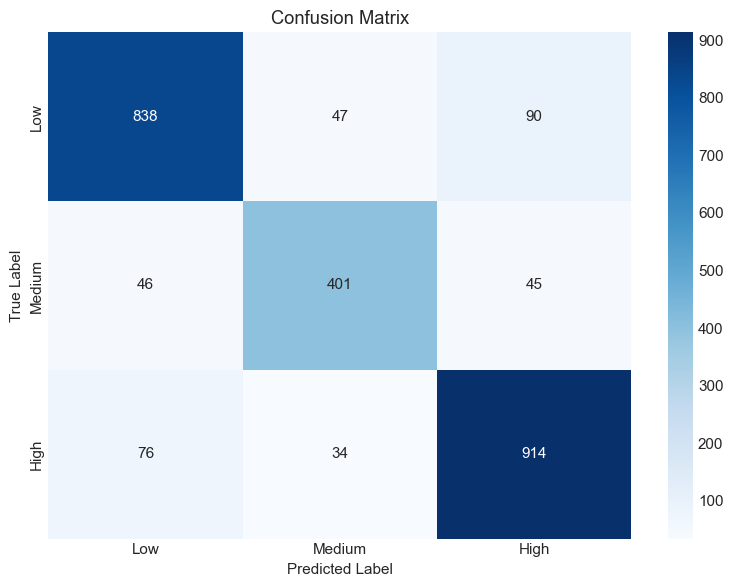

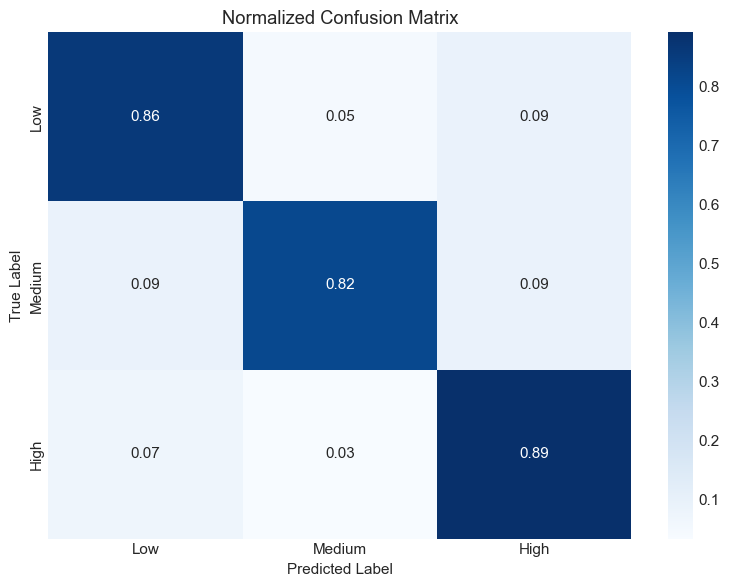

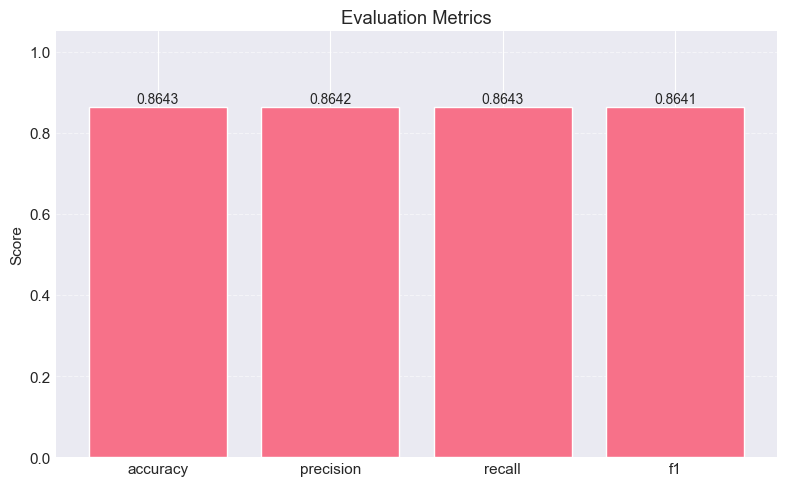

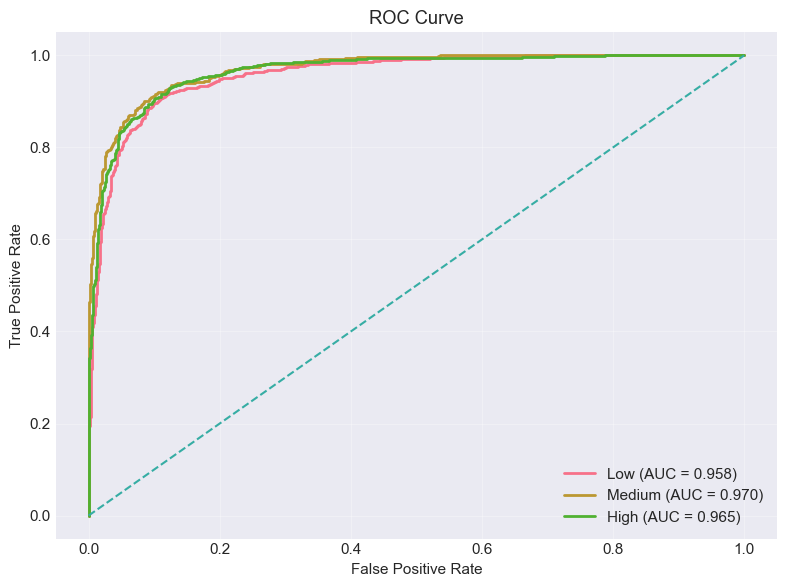

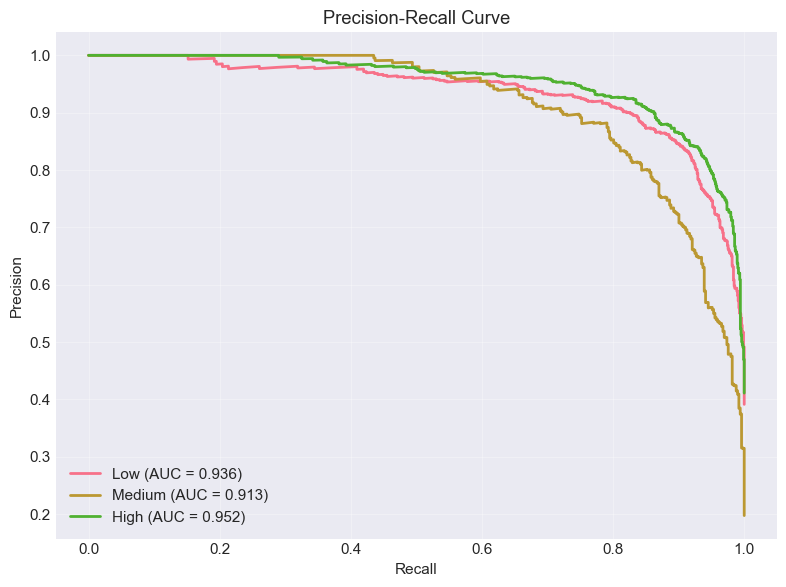


All evaluation files saved to:
./results/base_multimodal_cnn/


In [13]:
from src.eval_metrics import evaluate_model
import os
os.makedirs('results/base_multimodal_cnn/', exist_ok=True)


metrics, cm = evaluate_model(
    model=model,
    test_loader=test_loader,
    save_root="./results/base_multimodal_cnn/",
    class_names=[
        "Low",
        "Medium",
        "High",
    ],
    device='cuda'
)

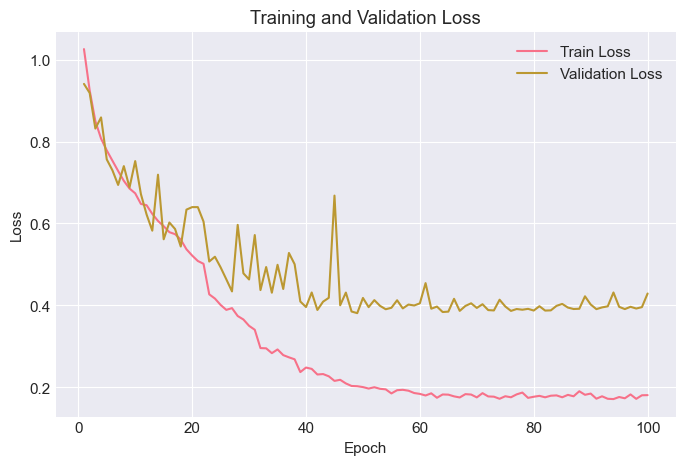

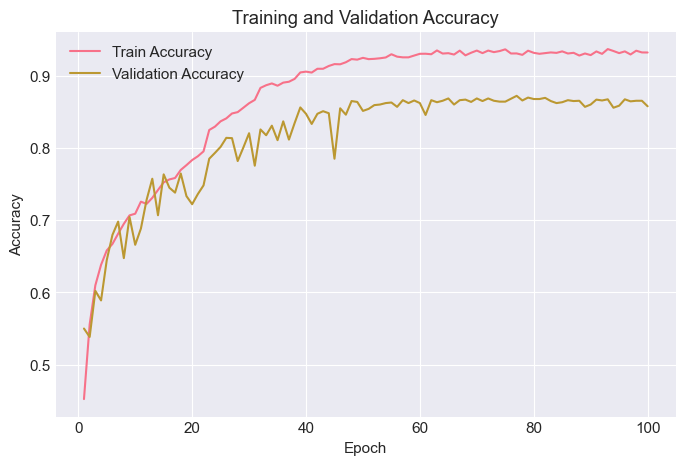

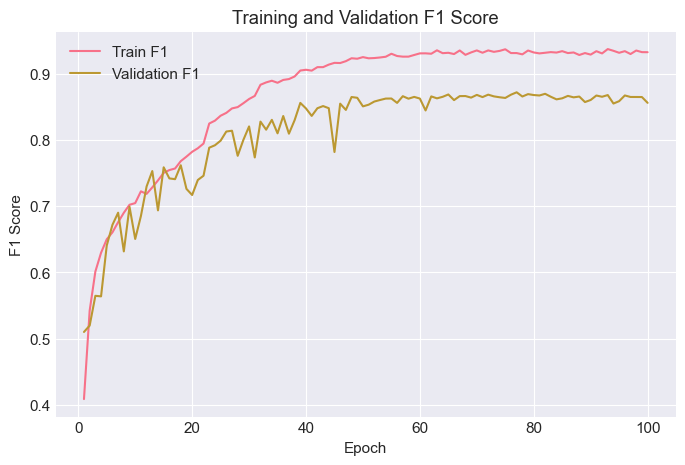

In [15]:
# Set style
import seaborn as sns
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 11

# Add these for consistent saving
plt.rcParams['savefig.facecolor'] = plt.rcParams['figure.facecolor']  # Use same as display
plt.rcParams['savefig.edgecolor'] = plt.rcParams['figure.edgecolor']
plt.rcParams['savefig.transparent'] = False  # Set to True if you want transparent background


# PLOT TRAINING HISTORY
def plot_training_history(history):

    epochs = range(1, len(history["train_loss"]) + 1)

    # ================= LOSS =================

    plt.figure(figsize=(8, 5))

    plt.plot(epochs, history["train_loss"], label='Train Loss')
    plt.plot(epochs, history["val_loss"], label='Validation Loss')

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and Validation Loss")

    plt.legend()

    plt.grid(True)
    plt.savefig('results/base_multimodal_cnn/training_loss.png')
    plt.show()

    # ================= ACCURACY =================

    plt.figure(figsize=(8, 5))

    plt.plot(epochs, history["train_acc"], label='Train Accuracy')
    plt.plot(epochs, history["val_acc"], label='Validation Accuracy')

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Training and Validation Accuracy")

    plt.legend()

    plt.grid(True)
    plt.savefig('results/base_multimodal_cnn/training_accuracy.png')
    plt.show()

    # ================= F1 SCORE =================

    plt.figure(figsize=(8, 5))

    plt.plot(epochs, history["train_f1"], label='Train F1')
    plt.plot(epochs, history["val_f1"], label='Validation F1')

    plt.xlabel("Epoch")
    plt.ylabel("F1 Score")
    plt.title("Training and Validation F1 Score")

    plt.legend()

    plt.grid(True)
    plt.savefig('results/base_multimodal_cnn/training_F1Score.png')
    plt.show()


import os
os.makedirs('results/base_multimodal_cnn/', exist_ok=True)

# PLOT HISTORY
plot_training_history(history)